# GraphGuard · IBM HI-Small: từ một giao dịch đến quyết định review

**Lộ trình 30 phút:** 1. Đặt vấn đề (2′) → 2. Data/ETL/graph (6′) → 3. Degree/PageRank/motif/LPA (7′) → 4. Tạo features và model (10′) → 5. Kết quả/giới hạn (5′).

Notebook này trình bày **code thật của dự án** và đọc bảng/Parquet của **full run IBM 5.078.345 giao dịch**. Các hàm gốc được khai báo trong code cell để có thể đọc từng dòng; bảng bên dưới lấy từ run đã hoàn thành, **không phải output của việc gọi lại hàm**. Lần full run có nguồn, config và output riêng trong `system_state.json`. `head()` chỉ giới hạn số hàng *hiển thị*. Chạy bằng Windows `.venv\Scripts\python.exe`; PyArrow đọc artifact theo batch nên không cần mở Spark/JVM.

**Câu hỏi:** Một giao dịch nhìn riêng chỉ có người gửi, người nhận, loại và số tiền. Mạng giao dịch trước đó bổ sung điều gì để ưu tiên kiểm tra? Nhãn `isFraud` ở IBM nghĩa là giao dịch được simulator gán *laundering*; score không phải phán quyết về một người.

IBM AML Raw Data Context & Primary AML Variables**

Bộ dữ liệu gồm **5.078.345 giao dịch** với **5.177 ca rửa tiền có tổ chức** (tỷ lệ rủi ro nền cực thấp: **0,102%**).

| Tên biến thô (Raw Variable) | Kiểu dữ liệu | Ý nghĩa nghiệp vụ AML & Quyết định xử lý kỹ thuật |
| :--- | :--- | :--- |
| `Timestamp` | Text / String | Dấu thời gian giao dịch mô phỏng (định dạng `YYYY/MM/DD HH:MM`). Được chuyển đổi sang Unix epoch seconds làm trục tọa độ nhân quả bất biến. |
| `From_Bank` / `To_Bank` | Integer | Mã định danh ngân hàng gửi và nhận (gồm 11 ngân hàng: 0, 1, 2, ..., 12). Cần chuẩn hóa đệm số 0 để tránh phân mảnh danh tính. |
| `From_Account` / `To_Account` | String | Mã số tài khoản gửi và nhận. Tệp CSV gốc bị trùng tên cột `Account` &rarr; Cần đổi tên tường minh để tránh lỗi trích xuất Schema Spark. |
| `Amount_Received` / `Amount_Paid` | Float | Số tiền nhận và chuyển thực tế. Chênh lệch thể hiện phí giao dịch ngân hàng hoặc tỷ giá quy đổi ngoại tệ. |
| `Receiving_Currency` / `Payment_Currency` | String | 15 loại tiền tệ quốc tế (USD, EUR, GBP, SAR, CHF,...). Cần chuẩn hóa phân vị `q90` độc lập theo từng loại tiền để đưa về cùng thang đo rủi ro. |
| `Payment_Format` | String | Kênh thanh toán: `ACH`, `Wire`, `Cheque`, `Credit Card`, `Cash`. Tội phạm thường ưu tiên điện tín `Wire` hoặc thanh toán bù trừ `ACH` để chuyển số tiền lớn. |
| `Is_Laundering` | Integer (0/1) | Nhãn mục tiêu kiểm định thực tế (Ground Truth) do hệ thống mô phỏng đa tác nhân sinh ra theo các typology chuẩn của FATF. |


## 1. Đặt vấn đề · một giao dịch chỉ là một phần câu chuyện

Cycle `A → B → C → A` là ba giao dịch nối thành vòng. Cell đọc **ba cạnh thật đã lưu** của ví dụ trong bản trình bày gốc. Cột `src`/`dst` là tài khoản gửi/nhận, `step` là thời gian; `isFraud` là nhãn chỉ dùng để hậu kiểm. Có vòng chưa chứng minh cùng một khoản tiền đã quay về.

In [1]:
from pathlib import Path
import sys, json, hashlib, csv
import pandas as pd
import pyarrow.dataset as ds
from IPython.display import display, Image
repo = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p/'requirements.txt').exists() and (p/'src').is_dir())
sys.path.insert(0, str(repo))
run_dir = repo/'results/full_system/ibm_aml/run_20261024T081350344149Z'
checkpoint = repo/'results/presentation_checkpoint'
state = json.loads((run_dir/'system_state.json').read_text(encoding='utf-8'))
assert state['status']=='completed' and state['support']['n']==5_078_345
cycle = pd.read_csv(checkpoint/'ibm_aml/tables/selected_case_evidence.csv')
display(cycle.loc[cycle.evidence_kind=='chronological 3-cycle witness',
                  ['event_id','src','dst','step','type','amount','payment_currency','isFraud']].head(3))
print('Full run:',run_dir.name,'|',state['support']['n'],'transactions')

,event_id,src,dst,step,type,amount,payment_currency,isFraud
0,377957140586,222_811B83280,150240_812D22980,1662310140,ACH,660.96,Saudi Riyal,1.0
1,25769808489,150240_812D22980,119_811C597B0,1662453720,ACH,10005.08,Saudi Riyal,1.0
2,395137022447,119_811C597B0,222_811B83280,1662698760,ACH,52873.69,Saudi Riyal,1.0


Full run: run_20261024T081350344149Z | 5078345 transactions


## 2. Data · EDA → ETL → graph construction

### 2.1. EDA: nhãn nằm ở loại giao dịch nào?

**Code làm gì:** quét `type` và `isFraud` trên **toàn bộ** `transactions.parquet`, đếm số giao dịch, số positive rồi chia để có tỷ lệ. `type` là hình thức thanh toán, không phải nhãn. Output cần nói: phải nhìn cả *số lượng* và *tỷ lệ*, vì nhóm đông có thể có tỷ lệ positive thấp.

In [2]:
from collections import Counter
transactions = ds.dataset(str(run_dir/'transactions.parquet'), format='parquet')
counts, positives = Counter(), Counter()
for batch in transactions.scanner(columns=['type','isFraud'],batch_size=32768).to_batches():
    for kind,label in zip(batch.column(0).to_pylist(),batch.column(1).to_pylist()):
        counts[kind]+=1
        positives[kind]+=int(label)
by_type = pd.DataFrame([{'type':kind,'transactions':n,'positives':positives[kind],
                         'positive_rate':positives[kind]/n} for kind,n in counts.items()])
assert sum(counts.values())==state['support']['n']
display(by_type.sort_values('transactions',ascending=False))

,type,transactions,positives,positive_rate
0,Cheque,1864331,324,0.000174
2,Credit Card,1323324,206,0.000156
1,ACH,600797,4483,0.007462
3,Cash,490891,108,0.000220
4,Reinvestment,481056,0,0.000000
5,Wire,171855,0,0.000000
6,Bitcoin,146091,56,0.000383


### Amount, currency và thời gian · tại sao phải giữ bối cảnh?

`amount` là **Amount Paid theo payment_currency**, không quy đổi mọi currency sang USD. So con số Yen với USD trực tiếp sẽ sai đơn vị. `step` là epoch seconds; dữ liệu ở test đến sau dữ liệu train. Cell đầu in bảng phân bố theo currency và các khối thời gian **đã tính trên full data**; bảng thời gian giải thích vì sao phải kiểm tra model trên tương lai.

In [3]:
currency = pd.read_csv(checkpoint/'ibm_aml/tables/baseline_currencies.csv')
time_blocks = pd.read_csv(checkpoint/'common/tables/full_time_blocks.csv')
display(currency.head(8))
display(time_blocks.loc[time_blocks.astype(str).apply(lambda col:col.str.contains('ibm_aml',case=False)).any(axis=1)].head(6))

,payment_currency,count
0,US Dollar,1912
1,Euro,1372
2,Saudi Riyal,374
3,Swiss Franc,193
4,Yuan,184
5,Rupee,167
6,Yen,155
7,Ruble,133


,dataset,time_block,transactions,positives,first_step,last_step,first_time_UTC,last_time_UTC
0,ibm_aml,0,1013927,286,1661965200,1662040740,2022-08-31 17:00:00+00:00,2022-09-01 13:59:00+00:00
1,ibm_aml,1,1015757,761,1662040800,1662203520,2022-09-01 14:00:00+00:00,2022-09-03 11:12:00+00:00
2,ibm_aml,2,508335,699,1662203580,1662354720,2022-09-03 11:13:00+00:00,2022-09-05 05:12:00+00:00
3,ibm_aml,3,760846,809,1662354780,1662490020,2022-09-05 05:13:00+00:00,2022-09-06 18:47:00+00:00
4,ibm_aml,4,761659,823,1662490080,1662627900,2022-09-06 18:48:00+00:00,2022-09-08 09:05:00+00:00
5,ibm_aml,5,1017821,1799,1662627960,1663492680,2022-09-08 09:06:00+00:00,2022-09-18 09:18:00+00:00


### 2.2. ETL · một dòng CSV thành một cạnh

IBM CSV có hai cột tên `Account`: account gửi và account nhận. Hàm ETL gốc đặt tên nội bộ `Account_Dest` cho cột thứ hai, chuẩn hóa bank ID (`010` và `10` thành cùng `10`), rồi tạo `src=bank_account gửi`, `dst=bank_account nhận`. `step` đổi từ timestamp; `type`, `amount`, hai currency và nhãn đi theo cạnh. Cell dưới chứa **nguyên hàm ETL gốc**; nhìn đoạn tạo `src`, `dst`, `step`, `isFraud`. Sau định nghĩa, bảng in 3 dòng raw và 3 dòng processed để thấy tên cột thay đổi; hai bảng chỉ minh họa schema, **không ghép theo thứ tự hàng**.

In [4]:
from __future__ import annotations
# Hàm gốc trong src/ibm_aml/etl.py; khai báo để đọc code, không tính lại full run.
def build_ibm_edges(spark: SparkSession, trans_csv_path: str) -> DataFrame:
    """Xay dung DataFrame Edges tu HI-Small_Trans.csv"""
    print(f"[*] Dang xu ly Edges tu: {trans_csv_path}")
    validate_csv_header(trans_csv_path, TRANS_HEADER)

    schema = StructType([
        StructField("Timestamp", StringType(), True),
        StructField("From Bank", StringType(), True),
        StructField("Account", StringType(), True),
        StructField("To Bank", StringType(), True),
        # Dat ten khong co dau cham: "Account.1" khien F.col("Account.1") bi
        # Spark hieu nham la truy cap truong long "1" ben trong struct
        # "Account" (dotted nested-field access), gay loi resolve. Doi ten
        # khong anh huong gia tri doc duoc, vi enforceSchema=true (mac dinh)
        # doc CSV theo VI TRI cot, khong theo ten header.
        StructField("Account_Dest", StringType(), True),
        StructField("Amount Received", DoubleType(), True),
        StructField("Receiving Currency", StringType(), True),
        StructField("Amount Paid", DoubleType(), True),
        StructField("Payment Currency", StringType(), True),
        StructField("Payment Format", StringType(), True),
        StructField("Is Laundering", ShortType(), True),
    ])

    raw_trans = spark.read.csv(trans_csv_path, header=True, schema=schema)

    # CHUAN HOA Bank ID: ep qua Long roi tra ve String truoc khi noi chuoi.
    # Ly do: StringType() (fix truoc do) chi dam bao Spark KHONG tu y lam mat
    # so 0 dau -- nhung khong dam bao Trans.csv va accounts.csv dung CHUNG 1
    # kieu dinh dang. Neu Trans.csv ghi "021174" con accounts.csv ghi "21174"
    # cho CUNG 1 ngan hang, composite key se KHONG BAO GIO khop du ca 2 deu
    # la StringType chinh xac. Ep qua Long xoa moi kieu dem so 0 mot cach
    # nhat quan tren ca 2 phia (edges va vertices), dam bao khop dung.
    from_bank_norm = F.col("From Bank").cast("long").cast("string")
    to_bank_norm = F.col("To Bank").cast("long").cast("string")

    edges_df = raw_trans.select(
        F.concat(from_bank_norm, F.lit("_"), F.col("Account")).alias("src"),
        F.concat(to_bank_norm, F.lit("_"), F.col("Account_Dest")).alias("dst"),
        F.col("Amount Paid").alias("amount"),
        # Giu them Amount Received + ca 2 currency de doi chieu/loc theo don
        # vi tien te sau nay -- KHONG duoc so sanh amount qua lai neu currency
        # khac nhau.
        F.col("Amount Received").alias("amount_received"),
        F.col("Payment Currency").alias("payment_currency"),
        F.col("Receiving Currency").alias("receiving_currency"),
        F.col("Payment Currency").alias("currency"),
        # Unix epoch second, KHONG PHAI hour-index nhu PaySim -- xem docstring
        F.unix_timestamp(F.col("Timestamp"), "yyyy/MM/dd HH:mm").cast("integer").alias("step"),
        F.to_timestamp(F.col("Timestamp"), "yyyy/MM/dd HH:mm").alias("timestamp"),
        F.col("Payment Format").alias("type"),
        F.col("Payment Format").alias("payment_format"),
        F.col("Is Laundering").alias("isFraud"),
        F.col("Is Laundering").alias("isLaundering"),
    )

    return edges_df

raw_path = repo/'data/raw/ibm_aml/HI-Small_Trans.csv'
with raw_path.open(newline='',encoding='utf-8-sig') as stream:
    raw_rows = list(csv.DictReader(stream))[:3]
display(pd.DataFrame(raw_rows)[['Timestamp','From Bank','Account','To Bank','Amount Paid','Payment Currency','Is Laundering']])
display(transactions.head(3,columns=['src','dst','step','type','amount','payment_currency','isFraud']).to_pandas())

,Timestamp,From Bank,Account,To Bank,Amount Paid,Payment Currency,Is Laundering
0,2022/09/01 00:20,010,8000EBD30,010,3697.34,US Dollar,0
1,2022/09/01 00:20,03208,8000F5340,001,0.01,US Dollar,0
2,2022/09/01 00:00,03209,8000F4670,03209,14675.57,US Dollar,0


,src,dst,step,type,amount,payment_currency,isFraud
0,70_100428738,10060_8044B0A90,1662598380,Cheque,36515.98,Yen,0.0
1,27621_80A110F30,15_80A20FB30,1662171780,ACH,2518.05,Australian Dollar,0.0
2,212_807669B50,121580_8088056D0,1662687900,Cheque,842.21,UK Pound,0.0


### 2.3. Graph construction · đỉnh và cạnh từ đâu ra?

**Đỉnh (`id`)** là account ghép bank + số account. **Cạnh (`src → dst`)** là một giao dịch, nên cùng cặp tài khoản có thể có nhiều cạnh; self-loop vẫn được giữ. `event_id` định danh từng giao dịch và dùng để nối các features/predictions về sau. Cell kiểm tra số đỉnh/cạnh full data và đối chiếu báo cáo null/dangling, không dùng 5 dòng hiển thị để suy ra tổng.

In [5]:
vertices = ds.dataset(str(repo/'data/processed/ibm_aml/vertices.parquet'),format='parquet')
edge_count,vertex_count=transactions.count_rows(),vertices.count_rows()
assert edge_count==state['integrity']['num_edges']
assert vertex_count==state['integrity']['num_vertices']
print({'vertices':vertex_count,'edges':edge_count,
       'dangling_edges':state['integrity']['dangling_edges'],
       'self_loops':state['integrity']['self_loops']})
display(transactions.head(3,columns=['event_id','src','dst','step','amount','type','isFraud']).to_pandas())

{'vertices': 518581, 'edges': 5078345, 'dangling_edges': 0, 'self_loops': 591212}


,event_id,src,dst,step,amount,type,isFraud
0,0,70_100428738,10060_8044B0A90,1662598380,36515.98,Cheque,0.0
1,1,27621_80A110F30,15_80A20FB30,1662171780,2518.05,ACH,0.0
2,2,212_807669B50,121580_8088056D0,1662687900,842.21,Cheque,0.0


## 3. Tín hiệu đồ thị · tài khoản nào, đường tiền nào, nhóm nào?

### 3.1. Degree · tài khoản giao dịch bao nhiêu lần?

Hàm gốc `account_degree_metrics` group cạnh theo `dst` để ra `inDegree`, theo `src` để ra `outDegree`, rồi cộng thành `degree`. Một self-loop góp **1 vào mỗi phía**. Vì mỗi cạnh có một đầu gửi và một đầu nhận, tổng mỗi loại degree bằng số cạnh. Bảng top chỉ giúp tìm account hoạt động nhiều; **degree cao không tự suy ra laundering**.

In [6]:
from __future__ import annotations
# Hàm gốc trong src/paysim/metrics.py; khai báo để đọc code, không tính lại full run.
def account_degree_metrics(ids, edges, ranks):
    """Keep every account, including isolates; count each transaction edge."""
    incoming = edges.groupBy("dst").count().select(
        F.col("dst").alias("id"), F.col("count").alias("inDegree"))
    outgoing = edges.groupBy("src").count().select(
        F.col("src").alias("id"), F.col("count").alias("outDegree"))
    return (
        ranks.join(incoming, "id", "left").join(outgoing, "id", "left")
        .fillna(0, subset=["inDegree", "outDegree"])
        .withColumn("degree", F.col("inDegree") + F.col("outDegree"))
    )

top_degree = pd.read_csv(run_dir/'top10_pagerank.csv')
print('Σ inDegree = Σ outDegree =',edge_count,'; Σ degree =',2*edge_count)
display(top_degree[['id','inDegree','outDegree','degree']].head(5))

Σ inDegree = Σ outDegree = 5078345 ; Σ degree = 10156690


,id,inDegree,outDegree,degree
0,40836_80F47A310,159,2,161
1,4726_808FAF7C0,90,1,91
2,39678_80F523260,84,2,86
3,3051_802508900,78,2,80
4,14277_80B847A90,85,1,86


### 3.2. PageRank · vị trí trong mạng khác số giao dịch

PageRank truyền rank theo **hướng cạnh**; tài khoản nhận từ những tài khoản có rank cao có thể tăng rank. Hàm gốc `pagerank_update` thực hiện **một vòng cập nhật**; full run lặp 10 vòng. Cột `pagerank` ở bảng là điểm của **account**, không phải xác suất laundering. ID trong bảng đúng là các account có PageRank cao.

In [7]:
from __future__ import annotations
# Hàm gốc trong src/paysim/metrics.py; khai báo để đọc code, không tính lại full run.
def pagerank_update(ids, weights, ranks, reset_probability):
    """One directed PageRank update, preserving physical-edge multiplicity."""
    incoming = (
        weights.join(ranks.select(F.col("id").alias("src"), "pagerank"), "src")
        .groupBy("dst")
        .agg(F.sum(F.col("pagerank") * F.col("weight")).alias("incoming"))
    )
    # A vertex without incoming messages receives only the reset term.
    return (
        ids.join(incoming.withColumnRenamed("dst", "id"), "id", "left")
        .select("id", (F.lit(reset_probability) + (1-reset_probability)
                * F.coalesce(F.col("incoming"), F.lit(0.0))).alias("pagerank"))
    )

display(top_degree[['id','pagerank','inDegree','outDegree']].head(5))
print('PageRank iterations:',state['config']['pagerank_iterations'])

,id,pagerank,inDegree,outDegree
0,40836_80F47A310,92.916825,159,2
1,4726_808FAF7C0,90.901724,90,1
2,39678_80F523260,88.309695,84,2
3,3051_802508900,85.792714,78,2
4,14277_80B847A90,84.680007,85,1


PageRank iterations: 10


### 3.3. Motif · tiền đi thành hình gì?

Bài xét **cycle ba đỉnh**, **relay**, **fan-in**, **fan-out**, **reciprocal**. Cycle là vòng `A→B→C→A`; relay là chuyển tiếp; fan-in gom nhiều nguồn; fan-out phân phối nhiều đích; reciprocal là hai chiều. Hàm gốc dưới tìm cycle account bằng GraphFrames và loại trường hợp đỉnh trùng. Bảng `baseline_summary.csv` ghi kết quả full graph; đó là cấu trúc/hậu kiểm, chưa phải dự đoán model.

In [8]:
from __future__ import annotations
from graphframes import GraphFrame
from pyspark.sql import DataFrame, functions as F
from src.motif.toy_cycle import MOTIF_PATTERN
def find_three_node_cycles(graph: GraphFrame) -> DataFrame:
    """Chạy đúng motif đã giao và loại các đường đóng có đỉnh trùng nhau."""
    return (
        graph.find(MOTIF_PATTERN)
        .where(
            (F.col("a.id") != F.col("b.id"))
            & (F.col("b.id") != F.col("c.id"))
            & (F.col("c.id") != F.col("a.id"))
        )
    )


baseline=pd.read_csv(run_dir/"baseline_summary.csv")
display(baseline)

,dataset,fraud_edges,label_audit_raw_cycles,directed_account_cycles,transaction_combinations,USD_above_10000_cycles
0,ibm_aml,5177,7473,54,2491,0


### Motif theo thời gian · chỉ nhìn lịch sử trước giao dịch

Trong code gốc, `build_motif_features` tạo các cột số từ lịch sử: 24h và 168h, bỏ giao dịch cùng thời điểm để tránh nhìn tương lai. Nó ghép kết quả star, reciprocal và cycle theo `event_id`; các Parquet stage giữ memory trong giới hạn. Đọc đoạn `build_star_features`, `build_reciprocal_features`, `build_temporal_cycle_features` trong hàm. Bảng output tóm tắt **toàn bộ dữ liệu**: motif có thể xuất hiện ở cả positive lẫn negative, nên không dùng motif làm kết luận tự động.

In [9]:
from __future__ import annotations
# Hàm gốc trong src/motif/features.py; khai báo để đọc code, không tính lại full run.
def build_motif_features(features: DataFrame, vertices: DataFrame, spec: DatasetSpec,
                         windows_hours: tuple[int, ...], *, cycle_builder=None,
                         topology_builder=None, checkpoint_dir=None) -> DataFrame:
    """Label-blind motifs with disk-backed stages and bounded heap residency."""
    require_unlabelled(features)
    from src.ibm_aml.motif_finding import build_temporal_cycle_features, find_topological_cycles
    root = checkpoint_dir or temporary_motif_directory()
    print("Features: star histories via expiry-prefix sums (disk checkpoint)", flush=True)
    stars = materialize_motif_stage(build_star_features(features, spec, windows_hours), root, "stars")
    print("Features: reciprocal and same-partner histories (disk checkpoint)", flush=True)
    reciprocal = materialize_motif_stage(build_reciprocal_features(features, spec, windows_hours), root, "reciprocal")
    combined = features.join(stars, "event_id", "left").join(reciprocal, "event_id", "left")
    for hours in windows_hours:
        # A->B->A is reciprocal, not a relay involving three distinct accounts.
        for family, subtract in (("fanin", "same_partner_count"), ("fanout", "same_partner_count"),
                                 ("relay", "reverse_relay_count")):
            combined = combined.withColumn(f"{family}_{hours}h", F.greatest(
                F.coalesce(F.col(f"{family}_{hours}h"), F.lit(0))
                - F.coalesce(F.col(f"{subtract}_{hours}h"), F.lit(0)), F.lit(0)))
    print("Features: directed topology and chronological cycle evidence (disk checkpoint)", flush=True)
    topology = materialize_motif_stage(
        (topology_builder or find_topological_cycles)(vertices, features), root, "topology")
    evidence = (cycle_builder or build_temporal_cycle_features)(topology, features).withColumn(
        "gap_seconds", F.col("gap_seconds") * spec.seconds_per_step
    ).where(F.col("gap_seconds") <= max(windows_hours) * 3600)
    cycles = evidence.groupBy("event_id").agg(
        F.count("*").cast("double").alias("cycle3_count"),
        F.max("amount_ratio").alias("cycle3_best_ratio"),
        F.min("gap_seconds").alias("cycle3_min_gap_seconds"),
        F.min(F.struct("first_event_id", "second_event_id")).alias("cycle3_witness"))
    # Ratio/gap extrema may come from different paths; witness is one real path.
    numeric = motif_numeric_columns(windows_hours)
    result = combined.join(cycles, "event_id", "left").fillna(0, subset=numeric)
    return materialize_motif_stage(result, root, "features")

coverage=pd.read_csv(run_dir/'motif_coverage.csv')
display(coverage[['scope','motif','covered_transactions','covered_positives',
                  'positive_fraction_when_present']].head(10))

,scope,motif,covered_transactions,covered_positives,positive_fraction_when_present
0,full,cycle3_count,304,92,0.302632
1,full,relay_24h,2493223,1393,0.000559
2,full,relay_168h,3516472,2427,0.000690
3,full,reciprocal_24h,1099,148,0.134668
4,full,reciprocal_168h,4455,305,0.068462
5,full,fanin_24h,1721890,2799,0.001626
6,full,fanin_168h,3286253,4016,0.001222
7,full,fanout_24h,2717315,1687,0.000621
8,full,fanout_168h,3251885,2295,0.000706
9,test,cycle3_count,132,41,0.310606


### 3.4. LPA · account thuộc nhóm nào?

LPA cho mỗi account một nhãn community bằng cách lặp bỏ phiếu từ hàng xóm. Hàm gốc `lpa_update` tính vote và chọn nhãn thắng. `member_count` đếm account trong nhóm, `internal_tx_count` là giao dịch trong nhóm, `cross_tx_count` là giao dịch đi qua biên; đây là ba mẫu số khác nhau. Bảng chỉ hiện 5 nhóm đầu từ **bảng tổng hợp full run**, không chọn mẫu cho thuật toán.

In [10]:
from __future__ import annotations
# Hàm gốc trong src/paysim/community_detection.py; khai báo để đọc code, không tính lại full run.
def lpa_update(links, labels):
    """Synchronous weighted neighbor voting; deterministic minimum-label tie."""
    messages = links.join(labels.select(
        F.col("id").alias("neighbor"), F.col("label").alias("neighbor_label")), "neighbor")
    votes = messages.groupBy("id", "neighbor_label").agg(F.sum("multiplicity").alias("votes"))
    # Lexicographic min(-votes, label) = most votes, then smallest label.
    winner = votes.groupBy("id").agg(F.min(F.struct(
        (-F.col("votes")).alias("negative_votes"),
        F.col("neighbor_label").alias("label"))).alias("winner"))
    winner = winner.select("id", F.col("winner.label").alias("new_label"))
    # Isolates receive no message and keep their current label.
    return labels.join(winner, "id", "left").select(
        "id", F.coalesce("new_label", "label").alias("label"))

communities=pd.read_csv(run_dir/'community_top50.csv')
display(communities[['label','member_count','internal_tx_count','cross_tx_count','positive_tx_count']].head(5))

,label,member_count,internal_tx_count,cross_tx_count,positive_tx_count
0,2841208552804025435,6935,8289,33830,69
1,-6017008472124481862,4870,6293,25909,45
2,-1845136380396678331,2327,2278,177587,248
3,1645034660210658271,1212,902,108241,166
4,-403586342733232231,883,1050,4536,2


### 3.5. Kết nối các tín hiệu

Degree/PageRank nói về **vị trí account**; motif nói về **đường giao dịch**; LPA nói về **nhóm account**. Để dự đoán *một giao dịch*, cả ba phải được nối về cùng `event_id`. Cell in bảng đóng góp/đối chiếu đã lưu; đọc đây như quan sát, không như bằng chứng một tín hiệu gây ra kết quả.

In [11]:
contributions=pd.read_csv(run_dir/'graph_contributions.csv')
display(contributions.head(8))

,contrast,enhanced,reference,delta_precision,delta_recall,delta_F1,delta_average_precision
0,motif_alone,motif_assisted,transaction_only,0.016004,-0.224569,-0.001661,0.000451
1,centrality_alone,transaction_centrality,transaction_only,0.000802,0.008338,0.001552,0.002121
2,community_alone,transaction_community,transaction_only,0.000000,0.000000,0.000000,0.000000
3,all_graph,full_fusion,transaction_only,0.010216,-0.205114,-0.004645,0.002466
4,motif_in_fusion,full_fusion,without_motifs,0.012535,-0.225125,-0.002269,-0.000879
5,centrality_in_fusion,full_fusion,without_centrality,-0.005788,0.019455,-0.002985,0.002015
6,community_in_fusion,full_fusion,without_community,-0.008598,0.011673,-0.007128,0.000403


## 4. Theo một giao dịch · từ bối cảnh đến score

### 4.1. Chọn cùng một giao dịch xuyên suốt

Cell lấy **một TP đã lưu** chỉ để theo dấu các cột. `event_id` này xuất hiện trong `transactions.parquet`, `features.parquet` và predictions; model vẫn được học/chấm trên full train/test. Các bảng tiếp theo đều là **cùng event_id**. `step` là thời điểm cần ra quyết định; `snapshot_as_of` phải sớm hơn.
**Bảng trước/sau:** Các cell dưới dùng cùng 10 `event_id` để xem cột được bổ sung dần. `head(10)` chỉ giới hạn hàng hiển thị; phần tính features và model của run gốc vẫn dùng full data. Event 3588 là ca chính có vector đã lưu để đối chiếu đúng trước/sau khi đưa vào model.


In [12]:
analysis_dir=repo/'results/notebook_analysis/ibm_aml/20261103T082504954563Z'
example_id=int(pd.read_csv(analysis_dir/'bridge_transaction.csv').iloc[0]['event_id'])
features=ds.dataset(str(run_dir/'features.parquet'),format='parquet')
example=features.to_table(filter=ds.field('event_id')==example_id).to_pandas()
assert len(example)==1 and 'isFraud' not in features.schema.names
# Cùng 10 event để đối chiếu bảng trước và sau khi thêm từng nhóm cột.
preview_ids=features.head(10,columns=['event_id']).column('event_id').to_pylist()
preview_raw=transactions.to_table(filter=ds.field('event_id').isin(preview_ids),
    columns=['event_id','src','dst','step','type','amount','payment_currency','receiving_currency']).to_pandas()
preview_raw=preview_raw.set_index('event_id').loc[preview_ids].reset_index()
preview_features=features.to_table(filter=ds.field('event_id').isin(preview_ids)).to_pandas()
preview_features=preview_features.set_index('event_id').loc[preview_ids].reset_index()
model_vector=pd.read_csv(analysis_dir/'bridge_model_vector.csv')
assert example_id==3588 and len(model_vector)==42
print('event_id minh họa vector:',example_id)
display(example[['event_id','src','dst','step','type','amount','payment_currency','snapshot_as_of']])
print("Trước thêm graph features · cùng 10 event:")
display(preview_raw.head(10))


event_id minh họa vector: 3588


,event_id,src,dst,step,type,amount,payment_currency,snapshot_as_of
0,3588,1665_80107B480,14804_806698470,1662805800,ACH,8643.99,US Dollar,1662627900


Trước thêm graph features · cùng 10 event:


,event_id,src,dst,step,type,amount,payment_currency,receiving_currency
0,532575953354,9665_80C4377A0,10057_803B19640,1662743160,Credit Card,9892.27,Yen,Yen
1,128849053906,19925_80C4472A0,10057_803B19640,1662657420,Credit Card,1953.86,Yen,Yen
2,343597409706,70_100428738,10057_803B1BA20,1662695340,Cheque,6417.61,Yen,Yen
3,103079245549,70_100428738,10057_803B1BA20,1662695280,Cash,8097.13,Yen,Yen
4,214748381665,70_100428738,10057_803B1BA20,1662756240,Cash,8097.13,Yen,Yen
5,395137011415,70_100428738,10057_803B1BA20,1662756840,Cheque,6417.61,Yen,Yen
6,188978575547,210972_8044A5C60,10057_803E254C0,1662657060,Credit Card,3313.64,Yen,Yen
7,489626297590,70_100428738,10057_803E254C0,1662632280,Cheque,290144.36,Yen,Yen
8,180388660882,70_100428738,10057_803E254C0,1662721080,Cheque,290144.36,Yen,Yen
9,420906829288,10099_803B09BA0,10057_803EBC780,1662674700,Cheque,62397556.51,Yen,Yen


### 4.2. T · năm cột từ giao dịch gốc

`type_index` và `currency_index` là mã category **fit trên train**; con số mã không thể đọc như mức rủi ro. `scaled_amount=log1p(amount / Q90)` với Q90 theo **currency × type của train**; `unseen_amount_group=1` nếu nhóm chưa có Q90; `fx_payment=1` khi hai currency khác nhau. Hàm gốc `_prepare_amounts` cho thấy đúng công thức. Bảng của event in giá trị *trước biến đổi*; cột sau biến đổi sẽ đi vào vector sau khi fit preprocessing.
**Before/after cần chỉ trên màn hình:** bảng 10 dòng trước có `type`, `amount`, hai currency nhưng chưa có `type_index`, `scaled_amount`. Vector đã lưu của event 3588 ở cell 4.6 mới hiện giá trị T sau preprocessing train.


In [13]:
from __future__ import annotations
# Hàm gốc trong src/motif/modeling.py; khai báo để đọc code, không tính lại full run.
def _prepare_amounts(features: DataFrame, scales: DataFrame) -> DataFrame:
    """Use training q90 of each currency/type; never compare nominal currencies."""
    joined = features.join(scales, ["payment_currency", "type"], "left")
    denominator = F.greatest(F.coalesce(F.col("training_q90"), F.lit(1.0)), F.lit(1e-12))
    return joined.withColumn("scaled_amount", F.log1p(F.least(F.col("amount") / denominator, F.lit(1e12)))).withColumn(
        "unseen_amount_group", F.col("training_q90").isNull().cast("double")
    ).withColumn("fx_payment", (F.col("payment_currency") != F.col("receiving_currency")).cast("double"))

display(example[['event_id','type','amount','payment_currency','receiving_currency']])
from src.motif.config import FullSystemConfig
from src.motif.modeling import family_feature_names
config=FullSystemConfig()
print('T →',family_feature_names('transaction_only',config.analysis))
print("T trước preprocessing · 10 giao dịch:")
display(preview_raw[["event_id","type","amount","payment_currency","receiving_currency"]].head(10))
print("T sau preprocessing · event 3588 trong vector model đã lưu:")
display(model_vector[model_vector.feature.isin(family_feature_names("transaction_only",config.analysis))])


,event_id,type,amount,payment_currency,receiving_currency
0,3588,ACH,8643.99,US Dollar,US Dollar


T → ['type_index', 'currency_index', 'scaled_amount', 'unseen_amount_group', 'fx_payment']
T trước preprocessing · 10 giao dịch:


,event_id,type,amount,payment_currency,receiving_currency
0,532575953354,Credit Card,9892.27,Yen,Yen
1,128849053906,Credit Card,1953.86,Yen,Yen
2,343597409706,Cheque,6417.61,Yen,Yen
3,103079245549,Cash,8097.13,Yen,Yen
4,214748381665,Cash,8097.13,Yen,Yen
5,395137011415,Cheque,6417.61,Yen,Yen
6,188978575547,Credit Card,3313.64,Yen,Yen
7,489626297590,Cheque,290144.36,Yen,Yen
8,180388660882,Cheque,290144.36,Yen,Yen
9,420906829288,Cheque,62397556.51,Yen,Yen


T sau preprocessing · event 3588 trong vector model đã lưu:


,feature,actual_model_input
0,type_index,0.000000
1,currency_index,12.000000
2,scaled_amount,0.103781
3,unseen_amount_group,0.000000
4,fx_payment,0.000000


### 4.3. C · cột từ snapshot degree/PageRank

Hàm `historical_system_snapshot` chỉ lấy cạnh có `step <= cutoff`, tính degree/PageRank/LPA rồi lưu `as_of_step`. `join_system_snapshot` nối snapshot hai lần theo `src` và `dst` và **từ chối** giao dịch có `step <= cutoff`. Vì thế `src_degree`, `dst_pagerank` mô tả hai account **trước** event; `*_seen=0` nghĩa account chưa có trong snapshot, cần đọc kèm các giá trị 0. Output là cùng event ở trên.
**Cột mới:** `src_*` và `dst_*` được tra từ snapshot quá khứ theo hai đầu giao dịch. Bảng sau cell hiện 10 hàng cùng `event_id` ở bước T, nhưng đã có thêm 10 cột C; `seen` giúp đọc giá trị 0 khi account chưa xuất hiện.


In [14]:
from __future__ import annotations
# Hàm gốc trong src/motif/pipeline.py; khai báo để đọc code, không tính lại full run.
def join_system_snapshot(transactions, snapshot):
    """Join one snapshot to a strictly later block without changing its rows."""
    from src.motif.config import CENTRALITY_COLUMNS, COMMUNITY_COLUMNS
    from src.motif.evaluation import require_unlabelled
    require_unlabelled(transactions)
    names = ["inDegree", "outDegree", "degree", "pagerank", "community_size", "community_cross_fraction", "community_out_transactions"]
    result = transactions
    if snapshot is None:
        for name in [*CENTRALITY_COLUMNS, *COMMUNITY_COLUMNS]:
            result = result.withColumn(name, F.lit(0.0))
        return result.withColumn("snapshot_as_of", F.lit(None).cast("long"))
    require_unlabelled(snapshot)
    cuts = snapshot.select("as_of_step").distinct().limit(2).collect()
    if len(cuts) != 1 or transactions.where(F.col("step") <= cuts[0].as_of_step).limit(1).count():
        raise ValueError("Every decision row must strictly follow one snapshot cutoff")
    for side in ("src", "dst"):
        lookup = snapshot.select(F.col("id").alias(side), F.lit(1.0).alias(side+"_seen"),
            F.col("community_key").alias(side+"_community_key"), *[F.col(n).cast("double").alias(side+"_"+n) for n in names])
        result = result.join(lookup, side, "left")
    seen = (F.coalesce(F.col("src_seen"), F.lit(0))==1) & (F.coalesce(F.col("dst_seen"), F.lit(0))==1)
    result = result.withColumn("community_endpoints_seen", seen.cast("double")).withColumn(
        "same_community", (seen & (F.col("src_community_key")==F.col("dst_community_key"))).cast("double"))
    return result.fillna(0, subset=[*CENTRALITY_COLUMNS, *COMMUNITY_COLUMNS]).drop("src_community_key", "dst_community_key").withColumn(
        "snapshot_as_of", F.lit(int(cuts[0].as_of_step)).cast("long"))

from src.motif.config import CENTRALITY_COLUMNS
print('C columns:',', '.join(CENTRALITY_COLUMNS))
display(example[['event_id','step','snapshot_as_of','src_seen','dst_seen',
                 'src_degree','dst_degree','src_pagerank','dst_pagerank']])
print("Sau khi nối C · cùng 10 event, T + 10 cột centrality:")
display(preview_features[["event_id","type","amount",*CENTRALITY_COLUMNS]].head(10))


C columns: src_inDegree, src_outDegree, src_degree, src_pagerank, src_seen, dst_inDegree, dst_outDegree, dst_degree, dst_pagerank, dst_seen


,event_id,step,snapshot_as_of,src_seen,dst_seen,src_degree,dst_degree,src_pagerank,dst_pagerank
0,3588,1662805800,1662627900,1.0,1.0,19.0,46.0,0.180974,0.317864


Sau khi nối C · cùng 10 event, T + 10 cột centrality:


,event_id,type,amount,src_inDegree,src_outDegree,src_degree,src_pagerank,src_seen,dst_inDegree,dst_outDegree,dst_degree,dst_pagerank,dst_seen
0,532575953354,Credit Card,9892.27,1.0,8.0,9.0,0.222679,1.0,3.0,2.0,5.0,1.281918,1.0
1,128849053906,Credit Card,1953.86,2.0,9.0,11.0,0.311432,1.0,3.0,2.0,5.0,1.281918,1.0
2,343597409706,Cheque,6417.61,53.0,10809.0,10862.0,5.008456,1.0,18.0,17.0,35.0,0.187976,1.0
3,103079245549,Cash,8097.13,53.0,10809.0,10862.0,5.008456,1.0,18.0,17.0,35.0,0.187976,1.0
4,214748381665,Cash,8097.13,53.0,10809.0,10862.0,5.008456,1.0,18.0,17.0,35.0,0.187976,1.0
5,395137011415,Cheque,6417.61,53.0,10809.0,10862.0,5.008456,1.0,18.0,17.0,35.0,0.187976,1.0
6,188978575547,Credit Card,3313.64,1.0,8.0,9.0,0.223147,1.0,9.0,13.0,22.0,0.177643,1.0
7,489626297590,Cheque,290144.36,53.0,10809.0,10862.0,5.008456,1.0,9.0,13.0,22.0,0.177643,1.0
8,180388660882,Cheque,290144.36,53.0,10809.0,10862.0,5.008456,1.0,9.0,13.0,22.0,0.177643,1.0
9,420906829288,Cheque,62397556.51,41.0,19.0,60.0,0.250192,1.0,23.0,15.0,38.0,0.396001,1.0


### 4.4. M · cột từ motif lịch sử

Hàm `build_star_features` tính vai trò gom/phân phối; `build_reciprocal_features` kiểm tra chiều ngược; cycle tính ba cạnh hợp lệ. `fanin_168h` và `fanout_168h` là **số lượt lịch sử**, `relay_168h` là số đường chuyển tiếp, `reciprocal_168h` là chiều ngược, `cycle3_count` là số cycle. Cùng một event có thể bằng 0 ở vài cột; 0 không chứng minh không có laundering. Cell in tên cột model M và giá trị cùng event.
**Cột mới:** 19 cột M theo lịch sử 24h/168h được nối về từng `event_id`. Bảng 10 hàng cho thấy các cột count có thể bằng 0 hoặc khác 0; chúng là số lượt/mẫu hợp điều kiện, không phải nhãn.


In [15]:
from __future__ import annotations
# Hàm gốc trong src/motif/features.py; khai báo để đọc code, không tính lại full run.
def build_star_features(features: DataFrame, spec: DatasetSpec, windows_hours: tuple[int, ...]) -> DataFrame:
    """Role volumes before subtracting same-partner paths in build_motif_features.

    Star witnesses are resolved on demand with resolve_star_witness; computing
    min/max partner in every bounded frame is quadratic at large IBM hubs.
    """
    require_unlabelled(features)
    eligible = features.where((F.col("src") != F.col("dst")) & (F.col("amount") > 0)
                              & (F.col("payment_currency") == F.col("receiving_currency")))
    outgoing = eligible.select("event_id", "step", "type", "payment_currency",
        F.col("src").alias("account"), F.lit(0).alias("direction"))
    incoming = eligible.select("event_id", "step", "type", "payment_currency",
        F.col("dst").alias("account"), F.lit(1).alias("direction"))
    roles = outgoing.unionByName(incoming)
    is_in = F.col("direction") == 1
    relay_type = (F.col("type") == "TRANSFER") if spec.name == "paysim" else F.lit(True)
    keys = ["account", "payment_currency"]
    buckets = roles.groupBy(*keys, "step").agg(
        F.sum(F.when(is_in, 1).otherwise(0)).alias("incoming"),
        F.sum(F.when(~is_in, 1).otherwise(0)).alias("outgoing"),
        F.sum(F.when(is_in & relay_type, 1).otherwise(0)).alias("relay_incoming"))
    counts = _sweep_counts(buckets, keys, ["incoming", "outgoing", "relay_incoming"], spec, windows_hours)
    joined = roles.join(counts, [*keys, "step"])
    is_sender = F.col("direction") == 0
    relay_current = is_sender & ((F.col("type") == "CASH_OUT") if spec.name == "paysim" else F.lit(True))
    expressions = {}
    for hours in windows_hours:
        inc, out = F.col(f"incoming_{hours}h"), F.col(f"outgoing_{hours}h")
        expressions.update({
            f"sender_in_{hours}h": F.when(is_sender, inc),
            f"sender_out_{hours}h": F.when(is_sender, out),
            f"receiver_in_{hours}h": F.when(~is_sender, inc),
            f"receiver_out_{hours}h": F.when(~is_sender, out),
            f"fanin_{hours}h": F.when(~is_sender, inc),
            f"fanout_{hours}h": F.when(is_sender, out),
            f"relay_{hours}h": F.when(relay_current, F.col(f"relay_incoming_{hours}h")),
        })
    projected = joined.select("event_id", *[expression.alias(name) for name, expression in expressions.items()])
    return projected.groupBy("event_id").agg(*[F.max(name).alias(name) for name in expressions])

from src.motif.features import motif_numeric_columns
motif_cols=motif_numeric_columns(config.analysis.windows_hours)
print('M columns:',', '.join(motif_cols))
display(example[['event_id','fanin_168h','fanout_168h','relay_168h',
                 'reciprocal_168h','cycle3_count']])
print("Sau khi nối M · cùng 10 event, kèm 19 cột motif:")
display(preview_features[["event_id","src_degree","dst_degree",*motif_cols]].head(10))


M columns: sender_in_24h, sender_out_24h, receiver_in_24h, receiver_out_24h, fanin_24h, fanout_24h, relay_24h, reciprocal_24h, sender_in_168h, sender_out_168h, receiver_in_168h, receiver_out_168h, fanin_168h, fanout_168h, relay_168h, reciprocal_168h, cycle3_count, cycle3_best_ratio, cycle3_min_gap_seconds


,event_id,fanin_168h,fanout_168h,relay_168h,reciprocal_168h,cycle3_count
0,3588,10,0,0,0.0,0.0


Sau khi nối M · cùng 10 event, kèm 19 cột motif:


,event_id,src_degree,dst_degree,sender_in_24h,sender_out_24h,receiver_in_24h,receiver_out_24h,fanin_24h,fanout_24h,relay_24h,...,sender_out_168h,receiver_in_168h,receiver_out_168h,fanin_168h,fanout_168h,relay_168h,reciprocal_168h,cycle3_count,cycle3_best_ratio,cycle3_min_gap_seconds
0,532575953354,9.0,5.0,0,1,1,0,1,1,0,...,7,1,0,1,7,0,0.0,0.0,0.0,0
1,128849053906,11.0,5.0,0,0,0,0,0,0,0,...,5,0,0,0,5,0,0.0,0.0,0.0,0
2,343597409706,10862.0,35.0,21,1637,3,6,0,1634,21,...,9310,13,15,0,9297,50,0.0,0.0,0.0,0
3,103079245549,10862.0,35.0,21,1634,2,6,0,1632,21,...,9307,12,15,0,9295,50,0.0,0.0,0.0,0
4,214748381665,10862.0,35.0,38,1636,2,3,0,1634,38,...,9139,14,15,0,9125,45,0.0,0.0,0.0,0
5,395137011415,10862.0,35.0,38,1629,3,3,0,1626,38,...,9138,15,15,0,9123,45,0.0,0.0,0.0,0
6,188978575547,9.0,22.0,0,0,1,2,1,0,0,...,7,5,10,5,7,0,0.0,0.0,0.0,0
7,489626297590,10862.0,22.0,0,1530,0,4,0,1530,0,...,9502,5,12,0,9497,46,0.0,0.0,0.0,0
8,180388660882,10862.0,22.0,34,1787,1,2,1,1787,34,...,9281,6,10,1,9276,45,0.0,0.0,0.0,0
9,420906829288,60.0,38.0,6,2,2,2,0,0,6,...,17,21,14,4,0,39,0.0,0.0,0.0,0


### 4.5. L · cột từ community lịch sử

Cũng bằng `join_system_snapshot`, mỗi đầu `src`/`dst` nhận `community_size`, `community_cross_fraction`, `community_out_transactions`; `same_community` so hai nhãn. `community_endpoints_seen=0` thì phép so nhóm thiếu bối cảnh. Đây là giá trị **lúc snapshot**, không dùng nhãn community tính từ tương lai. Cell in đủ tên cột L và vài cột dễ giải thích của cùng event.
**Cột mới:** tám cột L mô tả community của hai đầu và việc hai đầu có cùng nhóm hay không. Bảng 10 hàng giữ vài cột M ở bên trái để thấy M vẫn còn sau khi thêm L.


In [16]:
from src.motif.config import COMMUNITY_COLUMNS
print('L columns:',', '.join(COMMUNITY_COLUMNS))
display(example[['event_id','src_community_size','dst_community_size',
                 'same_community','community_endpoints_seen']])
print("Sau khi nối L · cùng 10 event, M vẫn giữ và 8 cột community được thêm:")
display(preview_features[["event_id","fanin_168h","relay_168h",*COMMUNITY_COLUMNS]].head(10))


L columns: src_community_size, src_community_cross_fraction, src_community_out_transactions, dst_community_size, dst_community_cross_fraction, dst_community_out_transactions, same_community, community_endpoints_seen


,event_id,src_community_size,dst_community_size,same_community,community_endpoints_seen
0,3588,6.0,1.0,0.0,1.0


Sau khi nối L · cùng 10 event, M vẫn giữ và 8 cột community được thêm:


,event_id,fanin_168h,relay_168h,src_community_size,src_community_cross_fraction,src_community_out_transactions,dst_community_size,dst_community_cross_fraction,dst_community_out_transactions,same_community,community_endpoints_seen
0,532575953354,1,0,9.0,0.968750,64.0,1.0,0.000000,2.0,0.0,1.0
1,128849053906,0,0,3.0,0.842105,19.0,1.0,0.000000,2.0,0.0,1.0
2,343597409706,0,50,230.0,0.983208,11851.0,543.0,0.786912,3041.0,0.0,1.0
3,103079245549,0,50,230.0,0.983208,11851.0,543.0,0.786912,3041.0,0.0,1.0
4,214748381665,0,45,230.0,0.983208,11851.0,543.0,0.786912,3041.0,0.0,1.0
5,395137011415,0,45,230.0,0.983208,11851.0,543.0,0.786912,3041.0,0.0,1.0
6,188978575547,5,0,7.0,0.951613,62.0,1.0,0.923077,13.0,0.0,1.0
7,489626297590,0,46,230.0,0.983208,11851.0,1.0,0.923077,13.0,0.0,1.0
8,180388660882,1,45,230.0,0.983208,11851.0,1.0,0.923077,13.0,0.0,1.0
9,420906829288,4,39,6.0,0.870968,62.0,4.0,0.976048,167.0,0.0,1.0


### 4.6. Bốn nhóm → một hàng features → vector model

Hàm gốc `family_feature_names` là **allowlist**: baseline nhận T; `full_fusion` nhận T+C+M+L. `event_id`, `src`, `dst`, `isFraud` không vào vector. Năm cột T được xử lý khi fit train; C/M/L đã nằm trong `features.parquet`. Output cho thấy **42 cột** mà tree nhận và cột nào chưa tồn tại trước preprocessing.
**Trước/sau khi đưa vào model:** `features.parquet` chứa các cột giao dịch thô và C/M/L cho mọi event, chưa có năm cột T đã mã hóa/scale. Preprocessing fit trên train bổ sung T; allowlist chọn 5 cột cho `transaction_only` hoặc 42 cột cho `full_fusion`. Bảng vector 42 hàng ở dưới là **event 3588 đã lưu từ model thật**, một hàng cho mỗi cột và giá trị thực sự vào cây. Bảng 10 giao dịch chỉ minh họa schema, không phải 10 hàng dùng để fit lại.

**Nhìn 10 hàng và nói theo thứ tự:**

- **T (5 cột, baseline `transaction_only`):** lấy `type`, `payment_currency`, `amount`, `receiving_currency` từ giao dịch. Fit category index và Q90 amount theo currency × type **chỉ trên train**; tạo `type_index`, `currency_index`, `scaled_amount`, `unseen_amount_group`, `fx_payment`. Mục đích: mô tả giao dịch hiện tại và làm mốc so sánh.
- **C (10 cột):** snapshot trước event tính in/out-degree và PageRank, rồi join hai lần theo `src`/`dst`; thêm cờ `seen`. Mục đích: biết hai account đã giao dịch nhiều hay nằm ở vị trí nào trong mạng **trước khi** event diễn ra.
- **M (19 cột):** đếm fan-in, fan-out, relay, reciprocal trong 24/168 giờ lịch sử và cycle hợp điều kiện; nối kết quả về `event_id`. Mục đích: mô tả đường đi của tiền trước giao dịch, không dùng nhãn để tạo motif.
- **L (8 cột):** LPA trên snapshot cũ tạo community của mỗi account; join hai đầu để có size, tỷ lệ qua biên và cờ cùng nhóm. Mục đích: bổ sung bối cảnh nhóm trước event.
- **Đưa vào model:** `full_fusion` nhận T+C+M+L = **42 số**; `transaction_only` chỉ nhận T = **5 số**. `event_id`, account ID và `isFraud` không vào vector. Vector 42 dòng dưới đây là đúng một giao dịch **3588**, còn bảng `head(10)` chỉ giúp nhìn hình dạng bảng trước model.


In [17]:
from __future__ import annotations
# Hàm gốc trong src/motif/modeling.py; khai báo để đọc code, không tính lại full run.
def family_feature_names(family, config):
    # Explicit allowlists exclude label, witness/account IDs and future data.
    names = ["type_index", "currency_index", "scaled_amount", "unseen_amount_group", "fx_payment"]
    groups = {"motif": motif_numeric_columns(config.windows_hours),
              "centrality": CENTRALITY_COLUMNS, "community": COMMUNITY_COLUMNS,
              "novelty": ["src_seen", "dst_seen"]}
    for group in SYSTEM_FAMILY_GROUPS[family]:
        names += groups[group]
    return names

from src.motif.config import CENTRALITY_COLUMNS, COMMUNITY_COLUMNS, SYSTEM_FAMILY_GROUPS
from src.motif.features import motif_numeric_columns
base_cols=family_feature_names('transaction_only',config.analysis)
full_cols=family_feature_names('full_fusion',config.analysis)
assert len(base_cols)==5 and len(full_cols)==42
assert not {'event_id','src','dst','isFraud'}.intersection(full_cols)
print('Baseline:',len(base_cols),'columns; full_fusion:',len(full_cols),'columns')
print('Tạo ở preprocessing train:',[c for c in full_cols if c not in features.schema.names])
print("Trước model · 10 event, toàn bộ cột T thô + C/M/L đã lưu:")
raw_t=["event_id","type","amount","payment_currency","receiving_currency"]
model_ready=[c for c in full_cols if c in preview_features.columns]
with pd.option_context("display.max_columns",None,"display.width",240):
    display(preview_features[[*raw_t,*model_ready]].head(10))
print("Sau preprocessing · vector 42 feature thực tế của event 3588:")
display(model_vector.assign(group=model_vector.feature.map(lambda x: "T" if x in base_cols else "C" if x in CENTRALITY_COLUMNS else "M" if x in motif_cols else "L")))


Baseline: 5 columns; full_fusion: 42 columns
Tạo ở preprocessing train: ['type_index', 'currency_index', 'scaled_amount', 'unseen_amount_group', 'fx_payment']
Trước model · 10 event, toàn bộ cột T thô + C/M/L đã lưu:


,event_id,type,amount,payment_currency,receiving_currency,src_inDegree,src_outDegree,src_degree,src_pagerank,src_seen,dst_inDegree,dst_outDegree,dst_degree,dst_pagerank,dst_seen,sender_in_24h,sender_out_24h,receiver_in_24h,receiver_out_24h,fanin_24h,fanout_24h,relay_24h,reciprocal_24h,sender_in_168h,sender_out_168h,receiver_in_168h,receiver_out_168h,fanin_168h,fanout_168h,relay_168h,reciprocal_168h,cycle3_count,cycle3_best_ratio,cycle3_min_gap_seconds,src_community_size,src_community_cross_fraction,src_community_out_transactions,dst_community_size,dst_community_cross_fraction,dst_community_out_transactions,same_community,community_endpoints_seen
0,532575953354,Credit Card,9892.27,Yen,Yen,1.0,8.0,9.0,0.222679,1.0,3.0,2.0,5.0,1.281918,1.0,0,1,1,0,1,1,0,0.0,0,7,1,0,1,7,0,0.0,0.0,0.0,0,9.0,0.968750,64.0,1.0,0.000000,2.0,0.0,1.0
1,128849053906,Credit Card,1953.86,Yen,Yen,2.0,9.0,11.0,0.311432,1.0,3.0,2.0,5.0,1.281918,1.0,0,0,0,0,0,0,0,0.0,0,5,0,0,0,5,0,0.0,0.0,0.0,0,3.0,0.842105,19.0,1.0,0.000000,2.0,0.0,1.0
2,343597409706,Cheque,6417.61,Yen,Yen,53.0,10809.0,10862.0,5.008456,1.0,18.0,17.0,35.0,0.187976,1.0,21,1637,3,6,0,1634,21,0.0,50,9310,13,15,0,9297,50,0.0,0.0,0.0,0,230.0,0.983208,11851.0,543.0,0.786912,3041.0,0.0,1.0
3,103079245549,Cash,8097.13,Yen,Yen,53.0,10809.0,10862.0,5.008456,1.0,18.0,17.0,35.0,0.187976,1.0,21,1634,2,6,0,1632,21,0.0,50,9307,12,15,0,9295,50,0.0,0.0,0.0,0,230.0,0.983208,11851.0,543.0,0.786912,3041.0,0.0,1.0
4,214748381665,Cash,8097.13,Yen,Yen,53.0,10809.0,10862.0,5.008456,1.0,18.0,17.0,35.0,0.187976,1.0,38,1636,2,3,0,1634,38,0.0,45,9139,14,15,0,9125,45,0.0,0.0,0.0,0,230.0,0.983208,11851.0,543.0,0.786912,3041.0,0.0,1.0
5,395137011415,Cheque,6417.61,Yen,Yen,53.0,10809.0,10862.0,5.008456,1.0,18.0,17.0,35.0,0.187976,1.0,38,1629,3,3,0,1626,38,0.0,45,9138,15,15,0,9123,45,0.0,0.0,0.0,0,230.0,0.983208,11851.0,543.0,0.786912,3041.0,0.0,1.0
6,188978575547,Credit Card,3313.64,Yen,Yen,1.0,8.0,9.0,0.223147,1.0,9.0,13.0,22.0,0.177643,1.0,0,0,1,2,1,0,0,0.0,0,7,5,10,5,7,0,0.0,0.0,0.0,0,7.0,0.951613,62.0,1.0,0.923077,13.0,0.0,1.0
7,489626297590,Cheque,290144.36,Yen,Yen,53.0,10809.0,10862.0,5.008456,1.0,9.0,13.0,22.0,0.177643,1.0,0,1530,0,4,0,1530,0,0.0,46,9502,5,12,0,9497,46,0.0,0.0,0.0,0,230.0,0.983208,11851.0,1.0,0.923077,13.0,0.0,1.0
8,180388660882,Cheque,290144.36,Yen,Yen,53.0,10809.0,10862.0,5.008456,1.0,9.0,13.0,22.0,0.177643,1.0,34,1787,1,2,1,1787,34,0.0,45,9281,6,10,1,9276,45,0.0,0.0,0.0,0,230.0,0.983208,11851.0,1.0,0.923077,13.0,0.0,1.0
9,420906829288,Cheque,62397556.51,Yen,Yen,41.0,19.0,60.0,0.250192,1.0,23.0,15.0,38.0,0.396001,1.0,6,2,2,2,0,0,6,0.0,39,17,21,14,4,0,39,0.0,0.0,0.0,0,6.0,0.870968,62.0,4.0,0.976048,167.0,0.0,1.0


Sau preprocessing · vector 42 feature thực tế của event 3588:


,feature,actual_model_input,group
0,type_index,0.000000,T
1,currency_index,12.000000,T
2,scaled_amount,0.103781,T
3,unseen_amount_group,0.000000,T
4,fx_payment,0.000000,T
5,src_inDegree,2.000000,C
6,src_outDegree,17.000000,C
7,src_degree,19.000000,C
8,src_pagerank,0.180974,C
9,src_seen,1.000000,C


### 4.7. Học model và chấm score

`prepare_training_prefix` fit Q90, category index và class weight **chỉ trên train cũ**. `fit_prepared_model` ghép `VectorAssembler` với `DecisionTreeClassifier` (depth 5, tối thiểu 50 dòng/lá). `score_transactions` tạo `risk_score` từ xác suất lớp positive; nhãn được nối **sau khi score** để đánh giá. Hai cell dưới chứa code gốc và bảng score đã lưu của cùng event; các hàm chỉ được khai báo, **không fit lại 5 triệu dòng**.

In [18]:
from __future__ import annotations
# Hàm gốc trong src/motif/modeling.py; khai báo để đọc code, không tính lại full run.
def prepare_training_prefix(features, truth, train_end, config, *, spill_training=True):
    """Fit preprocessing only on this prefix, then materialize once on disk."""
    from pyspark import StorageLevel
    require_unlabelled(features)
    train = features.where(F.col("step") <= train_end)
    scales = train.where(F.col("amount") > 0).groupBy("payment_currency", "type").agg(
        F.percentile_approx("amount", 0.9, 10_000).alias("training_q90")
    ).persist(StorageLevel.DISK_ONLY)
    scales.count()
    labelled = _prepare_amounts(train, scales).join(truth.select("event_id", "isFraud"), "event_id")
    support = labelled.agg(F.count("*").alias("n"), F.sum("isFraud").alias("p")).first()
    n, p = int(support.n), int(support.p or 0)
    weight = math.sqrt((n-p)/p) if 0 < p < n else 1.0
    metadata = {"train_end": int(train_end), "rows": n, "fraud": p,
                "positive_class_weight": weight, "status": "fitted" if 0 < p < n else "abstain: one training class"}
    indexer = StringIndexer(inputCols=["type", "payment_currency"], outputCols=["type_index", "currency_index"],
                           stringOrderType="alphabetAsc", handleInvalid="keep").fit(labelled)
    encoded = indexer.transform(labelled).withColumn(
        "_weight", F.when(F.col("isFraud") == 1, weight).otherwise(1.0)
    ).persist(StorageLevel.DISK_ONLY if spill_training else StorageLevel.MEMORY_AND_DISK)
    encoded.count()
    return PreparedTraining(encoded, scales, indexer, metadata)

print('Train preprocessing: Q90 theo currency × type; StringIndexer; positive class weight')
print('Tree:',config.analysis.tree_depth,'depth,',config.analysis.minimum_leaf_rows,'min rows/leaf')

Train preprocessing: Q90 theo currency × type; StringIndexer; positive class weight
Tree: 5 depth, 50 min rows/leaf


In [19]:
from __future__ import annotations
# Hàm gốc trong src/motif/modeling.py; khai báo để đọc code, không tính lại full run.
def fit_prepared_model(prepared, family, config):
    """Train the same tree on a declared feature subset; reuse preprocessing."""
    from pyspark.ml import PipelineModel
    names = family_feature_names(family, config)
    if prepared.training["status"] != "fitted":
        return RiskModel(family, None, prepared.scales, names, dict(prepared.training))
    assembler = VectorAssembler(inputCols=names, outputCol="features", handleInvalid="error")
    tree = DecisionTreeClassifier(labelCol="isFraud", featuresCol="features", weightCol="_weight",
        maxDepth=config.tree_depth, maxBins=64, minInstancesPerNode=config.minimum_leaf_rows, seed=config.seed)
    fitted = Pipeline(stages=[assembler, tree]).fit(prepared.labelled)
    # The exported pipeline still accepts raw categories when it is reloaded.
    pipeline = PipelineModel(stages=[prepared.indexer, *fitted.stages])
    return RiskModel(family, pipeline, prepared.scales, names, dict(prepared.training))

prediction=ds.dataset(str(run_dir/'final_predictions.parquet'),format='parquet')
matched=prediction.to_table(filter=ds.field('event_id')==example_id).to_pandas()
print('Prediction rows for event:',len(matched))
display(matched.head(1))

Prediction rows for event: 1


,event_id,risk_score,alert,isFraud,event_key,step,src,dst,amount,type,...,receiving_currency,snapshot_as_of,time_block,src_seen,dst_seen,dataset,run_id,model,threshold,decision_policy
0,3588,0.780899,True,1.0,f9bc7ec9aa584e6d4fbc521eecf0e081d0c6f1adf650a5...,1662805800,1665_80107B480,14804_806698470,8643.99,ACH,...,US Dollar,1662627900,5,1.0,1.0,ibm_aml,run_20261024T081350344149Z,full_fusion,0.5,validation_F1_threshold


### 4.8. Chọn cấu hình theo thời gian

Walk-forward gồm ba lần: fit trên quá khứ → validate ở block kế tiếp. So các family trên **cùng số giao dịch**, chọn family và threshold trước khi mở test. `frozen_rules.json` lưu quyết định; bảng leaderboard là output từ full run. `full_fusion` ở đây là model được chọn trên validation, không phải chọn bằng cách nhìn test.

In [20]:
rules=json.loads((run_dir/'frozen_rules.json').read_text(encoding='utf-8'))
leaderboard=pd.read_csv(run_dir/'validation_leaderboard.csv')
print('Frozen selection:',rules['selection']['family'],'threshold=',rules['selection']['threshold'])
display(leaderboard[['family','threshold','mean_F1','worst_F1','folds']].head(9))

Frozen selection: full_fusion threshold= 0.5


,family,threshold,mean_F1,worst_F1,folds
0,full_fusion,0.5,0.108301,0.075552,3
1,without_community,0.5,0.107185,0.075552,3
2,without_centrality,0.5,0.106360,0.075552,3
3,motif_assisted,0.5,0.106078,0.075552,3
4,motif_assisted,0.7,0.088498,0.014475,3
5,without_centrality,0.7,0.088385,0.014475,3
6,without_community,0.7,0.088038,0.014475,3
7,full_fusion,0.7,0.087924,0.014475,3
8,full_fusion,0.3,0.075210,0.072334,3


## 5. Kết quả · thêm bối cảnh đồ thị giúp được bao nhiêu?

### 5.1. Baseline và selected trên cùng test

`transactions` và `fraud` là mẫu số chung. `TP` là alert đúng, `FP` là alert sai, `FN` là positive bị bỏ sót. Precision = TP/(TP+FP); recall = TP/(TP+FN); AP xét thứ tự score. Cell đọc bảng **full test 1.017.821 giao dịch** để tính chênh lệch; không gọi lại model.

In [21]:
metrics=pd.read_csv(run_dir/'test_metrics.csv').set_index('model')
result=metrics.loc[['transaction_only','full_fusion'],
                   ['transactions','fraud','alerts','TP','FP','FN','precision','recall','F1','average_precision']]
display(result)
print('Δ false positives:',int(result.loc['full_fusion','FP']-result.loc['transaction_only','FP']))

,transactions,fraud,alerts,TP,FP,FN,precision,recall,F1,average_precision
model,,,,,,,,,,
transaction_only,1017821,1799,9584,869,8715,930,0.090672,0.483046,0.152684,0.056203
full_fusion,1017821,1799,4956,500,4456,1299,0.100888,0.277932,0.148038,0.058669


Δ false positives: -4259


### 5.2. Một TP chưa đủ · còn FP và FN

Cell đọc ba ca **đã được run lưu sau khi score**: TP đúng, FP cảnh báo sai, FN bỏ sót. `risk_score` là đầu ra cây; `isFraud` chỉ dùng hậu kiểm. Một ca chỉ giải thích đường đi của quyết định, không thay thế metric toàn test.

In [22]:
cases=[]
for kind in ('TP','FP','FN'):
    rows=json.loads((checkpoint/f'ibm_aml/examples/examples_full_fusion_{kind}.json').read_text(encoding='utf-8'))
    row=rows[0]
    cases.append({'case':kind,'event_id':row['event_id'],'type':row['type'],
                  'risk_score':row['risk_score'],'alert':row['alert'],'truth':row['isFraud'],
                  'cycle3_count':row.get('cycle3_count')})
display(pd.DataFrame(cases))

,case,event_id,type,risk_score,alert,truth,cycle3_count
0,TP,352187347222,ACH,0.780899,True,1.0,0.0
1,FP,824633728923,ACH,0.879032,True,0.0,0.0
2,FN,601295425506,ACH,0.376515,False,1.0,0.0


### 5.3. Nếu chỉ được review một số giao dịch?

Bảng dùng **cùng K** cho baseline và selected, xếp theo score giảm dần rồi đếm TP trong top K. Hình đã lưu minh họa ngân sách review; kiểm SHA-256 trước khi mở. Đây là **một hình kết quả chính** của phần cuối.

,model,review_fraction,K,TP_at_K,precision_at_K,recall_at_K
0,transaction_only,0.001,1018,92,0.090373,0.051140
1,transaction_only,0.005,5090,488,0.095874,0.271262
2,transaction_only,0.010,10179,877,0.086158,0.487493
15,full_fusion,0.001,1018,105,0.103143,0.058366
16,full_fusion,0.005,5090,505,0.099214,0.280712
17,full_fusion,0.010,10179,789,0.077513,0.438577


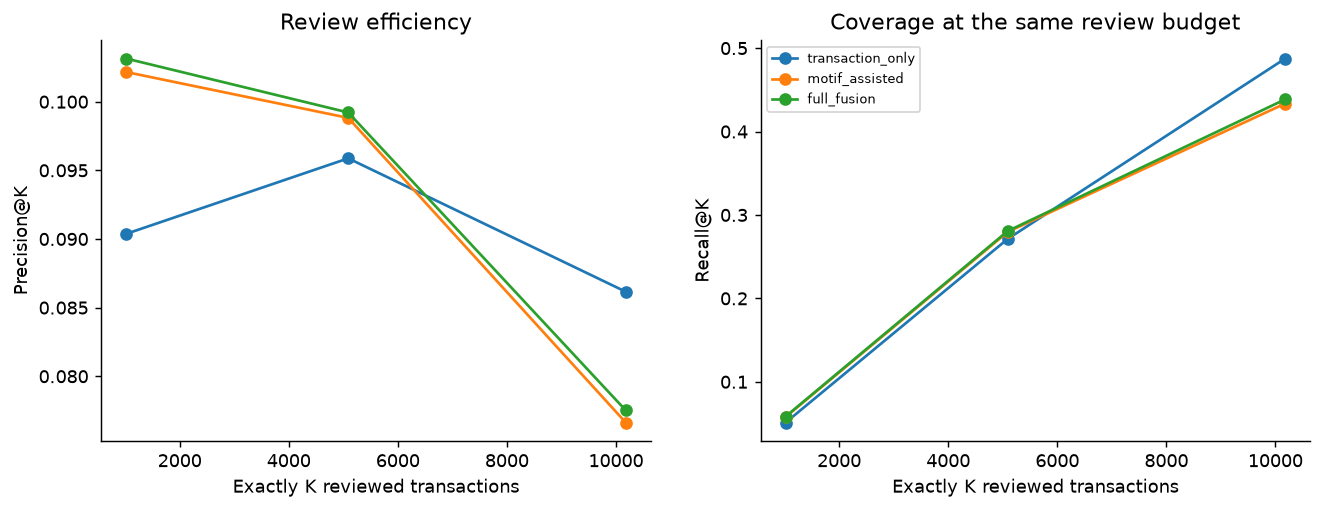

In [23]:
budget=pd.read_csv(run_dir/'review_budgets.csv')
display(budget[budget.model.isin(['transaction_only','full_fusion'])][
    ['model','review_fraction','K','TP_at_K','precision_at_K','recall_at_K']])
relative='ibm_aml/figures/review_budgets.png'
manifest=json.loads((checkpoint/'MANIFEST.json').read_text(encoding='utf-8'))
payload=(checkpoint/relative).read_bytes()
assert hashlib.sha256(payload).hexdigest()==manifest[relative]['sha256']
display(Image(data=payload))

### 5.4. Có ổn định theo thời gian không?

Test được chia thành các khoảng thời gian để xem kết quả có dao động hay không. Bảng dưới là toàn bộ các khoảng test đã lưu; khi thuyết trình chỉ cần nói: kết quả chung là trung bình của nhiều giai đoạn, **không hứa model hoạt động giống nhau mọi ngày**.

In [24]:
stability=pd.read_csv(run_dir/'test_temporal_stability.csv')
display(stability[stability.astype(str).apply(lambda c:c.str.contains('full_fusion')).any(axis=1)].head(8))

,model,test_period,threshold,transactions,fraud,alerts,TP,FP,FN,TN,precision,recall,F1,prevalence,alert_rate,precision_low95,precision_high95,recall_low95,recall_high95,average_precision
25,full_fusion,0,0.5,203929,205,737,44,693,161,203031,0.059701,0.214634,0.093418,0.001005,0.003614,0.044771,0.079198,0.163953,0.275813,0.028232
26,full_fusion,1,0.5,203134,141,1004,19,985,122,202008,0.018924,0.134752,0.033188,0.000694,0.004943,0.012148,0.029368,0.087993,0.200885,0.011307
27,full_fusion,2,0.5,203756,198,1028,56,972,142,202586,0.054475,0.282828,0.091354,0.000972,0.005045,0.042187,0.070080,0.224692,0.349231,0.028853
28,full_fusion,3,0.5,203828,159,928,42,886,117,202783,0.045259,0.264151,0.077277,0.000780,0.004553,0.033656,0.060611,0.201771,0.337658,0.024472
29,full_fusion,4,0.5,203174,1096,1259,339,920,757,201158,0.269261,0.309307,0.287898,0.005394,0.006197,0.245488,0.294438,0.282648,0.337297,0.168868


### 5.5. Kết luận · nói trong 30 giây

Nhóm biến giao dịch thành graph tài khoản, lấy ba loại bối cảnh **vị trí, đường tiền, cộng đồng** từ quá khứ, nối về từng `event_id` và đưa vào cây. Trên test IBM, `full_fusion` nâng precision **9,07% → 10,09%**, giảm FP **8.715 → 4.456**, nhưng recall giảm **48,30% → 27,79%**. Hệ thống giúp **ưu tiên review**, không tự kết luận giao dịch hay account phạm tội. Cycle, PageRank cao hoặc cùng community riêng lẻ không chứng minh laundering.

**Khi hỏi sâu:** `IBM_full_system.ipynb` có toàn bộ code thực thi; `system_state.json`, `frozen_rules.json` và `MANIFEST.json` ghi nguồn/kết quả. Notebook này chạy lại các phép đọc/đối chiếu full artifact và khai báo hàm gốc để giải thích; tính lại toàn pipeline cần một full run mới dưới guard của dự án.